# Simulating from the model

In [3]:
from models import prevalence_model, logPDF_prev
from mcmc import single_block_adapt_mcmc
import numpy as np
import pandas as pd
import seaborn as sns
from time import time
rng = np.random.default_rng(1)

In [4]:
model = prevalence_model.SingleRegionSingleAgeSEIRCompartmental(100)
beta_for_constant_R0 = [1] * model._num_betas

Final epidemic size: 0.5000503606031581


<AxesSubplot:xlabel='time', ylabel='nni'>

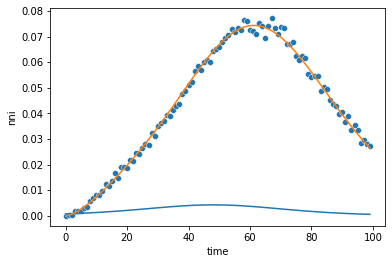

In [5]:
result_simple_raw = model.simulate(beta_for_constant_R0, 2, 2, 0.15, 1/1000, 0.75)
result_simple = pd.DataFrame({
    "time": range(100),
    "nni": result_simple_raw[0],
    "prev": result_simple_raw[1],
})
print("Final epidemic size: {}".format(result_simple_raw[2].R))
result_simple["num_tests"] = 15000
result_simple["num_positive"] = rng.binomial(result_simple["num_tests"], result_simple["prev"])
result_simple["observed_prev"] = result_simple["num_positive"] / result_simple["num_tests"]
sns.lineplot(x="time", y="nni", data=result_simple)
sns.lineplot(x="time", y="prev", data=result_simple)
sns.scatterplot(x="time", y="observed_prev", data=result_simple)

In [6]:
result_simple.to_csv("data/simulated/prev_model_simple.csv")

In [7]:
known_parameters = {
    "dL": 2,
    "dI": 2,
}
log_posterior = logPDF_prev.LogPosteriorOneRegion(forward_model=model, positive_num=result_simple["num_positive"],
    test_num=result_simple["num_tests"], fixed_params = known_parameters)
print("Estimating: {}".format(log_posterior._estimated_params))
log_posterior([0.15, np.log(1/1000), 0.75, 1] + beta_for_constant_R0)

Estimating: ('psir', 'i0', 'pi', 'beta_rw_sd', 'beta[0]', 'beta[1]', 'beta[2]', 'beta[3]', 'beta[4]', 'beta[5]', 'beta[6]', 'beta[7]', 'beta[8]', 'beta[9]', 'beta[10]', 'beta[11]', 'beta[12]', 'beta[13]')


-270993.6938016334

In [8]:
start_time = time()
true = [0.15, np.log(1/1000), 0.75, 1] + [0] * len(beta_for_constant_R0)
mcmc = single_block_adapt_mcmc.SingleBlockAMGS(log_posterior, true, iterations=2000)
mcmc_out = mcmc.run()
end_time = time()
print("Took {} seconds".format(end_time - start_time))

Running AMGS
Total number of iterations: 2000
Iteration 0 of 2000
Acceptance rate: 0.0
Invalid params
Iteration 1999 of 2000
Acceptance rate: 0.19899999999999995
Log target:  -509.3971959017609
Took 25.056276321411133 seconds


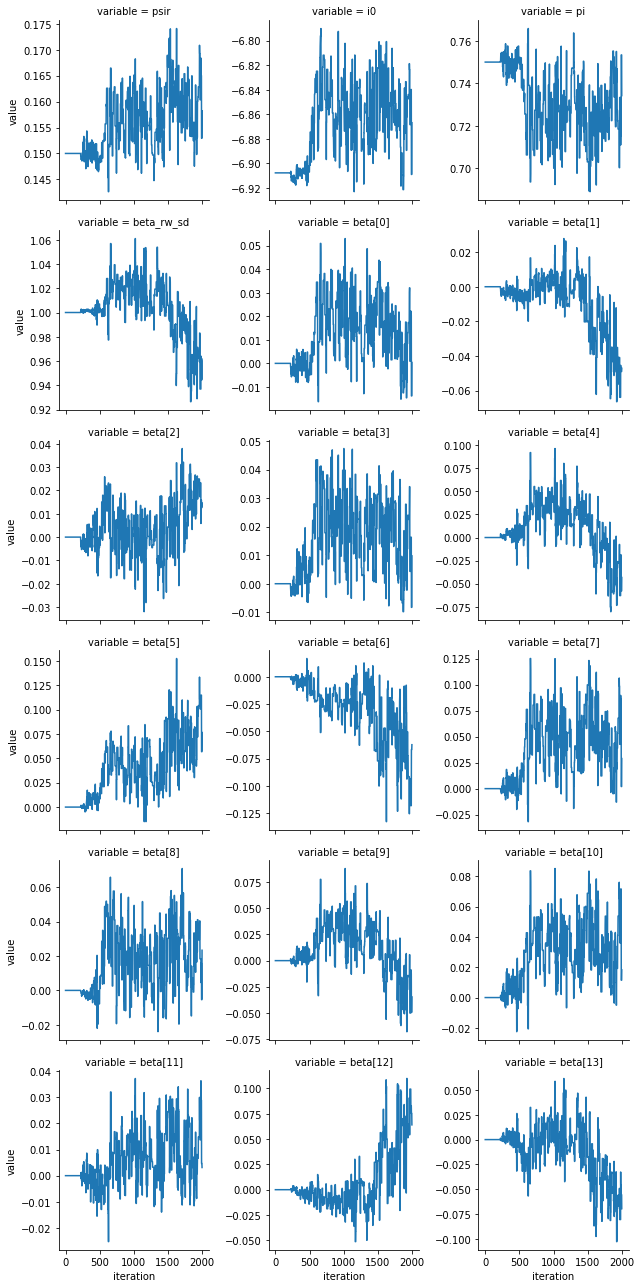

In [9]:
posterior = pd.DataFrame(
    data=mcmc_out,
    columns=log_posterior._estimated_params
)
posterior["iteration"] = posterior.index
posterior = posterior.melt(id_vars="iteration")
plt = sns.FacetGrid(posterior, col="variable", col_wrap=3, sharey=False)
plt.map(sns.lineplot, "iteration", "value")
#plt.map(sns.histplot, "value")

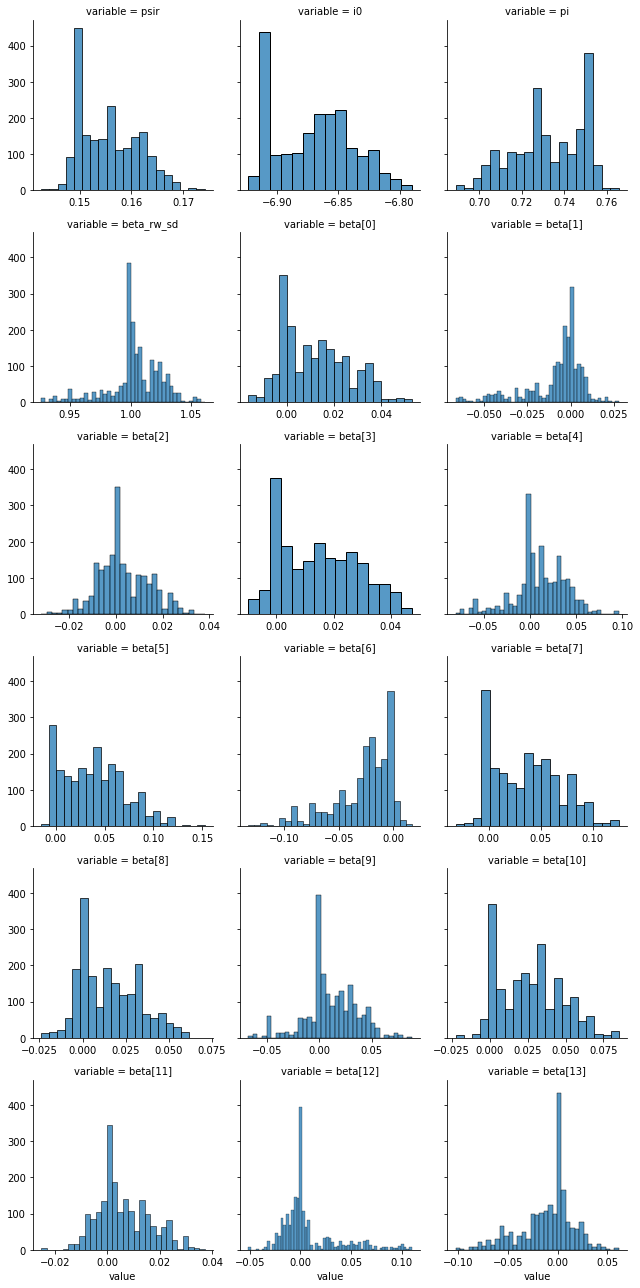

In [10]:
plt = sns.FacetGrid(posterior, col="variable", col_wrap=3, sharex=False)
plt.map(sns.histplot, "value")